# Analyse des ventes — Brasserie de la Fonderie

Jour 4 · mercredi 25 novembre 2026. Données fictives, prix hors TVA.

Les cellules de démonstration sont déjà écrites : exécutez-les (Ctrl+Entrée), modifiez-les. Les exercices s'écrivent dans les cellules vides.

Avant de rendre : « Restart », puis « Run All ».

## 1. Charger les ventes (J4-10 à J4-12)

Chemin « base » si votre connexion SQL Server de mardi marche, sinon chemin « fichier » : les deux donnent le même tableau.

In [1]:
import os
import pandas as pd
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
from sql.sql_connect import connecter_sql

CHEMIN = "base"

if CHEMIN == "base":
    from dotenv import load_dotenv
    from mssql_python import connect
    load_dotenv()
    conn = connecter_sql()
    cursor = conn.cursor()
    cursor.execute("SELECT date_vente, client, biere, format, quantite FROM ventes")
    colonnes = [d[0] for d in cursor.description]
    ventes = pd.DataFrame.from_records(cursor.fetchall(), columns=colonnes)
    ventes["date_vente"] = ventes["date_vente"].astype(str)
    cursor.close()
    conn.close()
else:
    ventes = pd.read_csv("../data/ventes.csv", sep=";")

ventes.head(3)

,date_vente,client,biere,format,quantite
0,2025-12-01,C04,B03,casier,5
1,2025-12-03,C01,B01,fut,5
2,2025-12-03,C02,B02,fut,8


In [2]:
ventes["quantite"].describe().round(2).to_dict()

{'count': 403.0,
 'mean': 4.1,
 'std': 2.04,
 'min': 1.0,
 '25%': 3.0,
 '50%': 4.0,
 '75%': 5.0,
 'max': 15.0}

In [3]:
# Erreur volontaire (J4-14) : décommentez, exécutez, puis recommentez.
ventes.shape

(403, 5)

In [4]:
ventes["quantite"].max()

np.int64(15)

## 2. Sélectionner et filtrer (J4-17 à J4-23)

In [5]:
print(ventes["biere"].head(3).tolist())
print(ventes[["client", "quantite"]].shape)

['B03', 'B01', 'B02']
(403, 2)


In [6]:
futs = ventes[ventes["format"] == "fut"]
print(len(futs))

243


In [7]:
# Erreur volontaire (J4-21) : décommentez, exécutez, puis recommentez.
# ventes[ventes["format"] == "fut" & ventes["quantite"] >= 10]

In [8]:
gros = ventes[(ventes["format"] == "fut") & (ventes["quantite"] >= 10)]
gros

,date_vente,client,biere,format,quantite
26,2025-12-19,C07,B01,fut,15
287,2026-08-07,C07,B05,fut,12
333,2026-09-18,C07,B01,fut,14


In [9]:
pont_taverne = ventes[ventes["client"].isin(["C01", "C03"])]
print(len(pont_taverne))

160


### Exercices 1.1 à 1.4

**1.1** Combien de lignes de ventes en casiers ?

In [10]:
print(len(ventes[ventes["format"] == "casier"]))

160


**1.2** Les fûts de La Braise (B03) : combien de lignes, combien de fûts ?

In [11]:
braise = ventes[(ventes["biere"] == "B03") & (ventes["format"] == "fut")]
print(len(braise), braise["quantite"].sum())

42 140


**1.3** Combien de commandes de 8 fûts ou plus ?

In [12]:
print(len(ventes[(ventes["format"] == "fut") & 
(ventes["quantite"] >= 8)]))

5


**1.4** Les ventes du Café du Pont (C01) et de la Taverne Saint-Jean (C03) depuis le 1er novembre 2026 : combien de lignes, de fûts ?

In [13]:
novembre = ventes[(ventes["client"].isin(["C01", "C03"])) & 
(ventes["date_vente"] >= "2026-11-01") & (ventes["format"] == "fut")]

print(len(novembre), novembre["quantite"].sum())

9 25


## 3. Nettoyer les commandes du site (J4-28 à J4-33)

In [14]:
site = pd.read_csv("../data/commandes_site.csv", sep=";", decimal=",")
site.info()

<class 'pandas.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   horodatage     26 non-null     str    
 1   client         25 non-null     str    
 2   biere          26 non-null     str    
 3   format         26 non-null     str    
 4   quantite       24 non-null     str    
 5   prix_unitaire  26 non-null     float64
dtypes: float64(1), str(5)
memory usage: 1.3 KB


In [15]:
print(site.isna().sum().to_dict())
print(site.duplicated().sum())

{'horodatage': 0, 'client': 1, 'biere': 0, 'format': 0, 'quantite': 2, 'prix_unitaire': 0}
2


In [16]:
site = site.drop_duplicates()
site["quantite"] = pd.to_numeric(site["quantite"], errors="coerce")
site["biere"] = site["biere"].str.strip().str.upper()
propres = site.dropna(subset=["client", "quantite"])
print(len(site), len(propres))

24 20


In [17]:
propres["montant"] = propres["quantite"] * propres["prix_unitaire"]
print(propres["montant"].sum())

3541.2


## 4. Regrouper (J4-34 à J4-39)

In [18]:
par_biere = futs.groupby("biere")["quantite"].sum()
par_biere

biere
B01    272
B02    166
B03    140
B04    111
B05    207
Name: quantite, dtype: int64

In [19]:
par_biere.sort_values(ascending=False).head(3)

biere
B01    272
B05    207
B02    166
Name: quantite, dtype: int64

In [20]:
resume = ventes.groupby("biere")["quantite"].agg(["sum", "mean"])
resume.round(1)

,sum,mean
biere,,
B01,473,4.2
B02,284,4.1
B03,300,3.8
B04,246,4.3
B05,349,4.1


In [21]:
ventes["client"].value_counts()

client
C01    83
C02    79
C03    77
C04    65
C05    64
C08    16
C06    15
C07     4
Name: count, dtype: int64

### Le journal du championnat (J4-39b)

Le fichier de la manche 1 s'appelle `manche1_journal.csv` ; s'il n'est pas dans `data/`, le journal d'exemple le remplace.

In [22]:
fichier = "../data/decisions.csv"
journal = pd.read_csv(fichier, sep=";")
print(journal["combat_id"].nunique(), "combats")
gagnants = journal[journal["issue"] == "gagne"].groupby("combat_id")["robot"].first()
print(len(gagnants), gagnants.value_counts().to_dict())

325 combats
304 {'mur': 85, 'danseur': 78, 'boxeur': 73, 'lutteur': 40, 'cogneur': 28}


### Exercices 2.0 à 2.4

**2.0** Rechargez `commandes_site.csv` et nettoyez-le sans regarder la démonstration : doublons, quantités, codes de bière, cases vides. Combien de lignes gardées, quel montant ?

In [23]:
site = pd.read_csv("../data/commandes_site.csv", sep=";", decimal=",")
site = site.drop_duplicates()                                          
site["quantite"] = pd.to_numeric(site["quantite"], errors="coerce")
site["biere"] = site["biere"].str.strip().str.upper()
propres = site.dropna(subset=["client", "quantite"])
propres["montant"] = propres["quantite"] * propres["prix_unitaire"]
print(len(propres), propres["montant"].sum())

20 3541.2


**2.1** Le top 3 des clients en fûts.

In [57]:
futs = propres[propres["format"] == "fut"]
futs.groupby("client")["quantite"].sum().sort_values(ascending=False).head(3)

client
C02    11.0
C01    10.0
C03     7.0
Name: quantite, dtype: float64

**2.2** Les casiers par bière, du plus vendu au moins vendu.

In [58]:

casiers = propres[propres["format"] == "casier"]
casiers.groupby("biere")["quantite"].sum().sort_values(ascending=False)

biere
B01    18.0
B05    16.0
B02    12.0
B04     8.0
B03     6.0
Name: quantite, dtype: float64

**2.3** Le journal : combien de combats ? Qui a gagné combien de fois ? (le nom du gagnant est dans `robot_a` si `vainqueur` vaut `a`, dans `robot_b` s'il vaut `b`)

In [85]:
fichier = "../data/exemple_journal.csv"
journal = pd.read_csv(fichier, sep=";")
fins = journal.groupby("combat_id").tail(1)
print(len(fins))
colonne_vainqueur_a_b = fins["vainqueur"] #soit a soit b
vainqueurs_a_lignes = fins[colonne_vainqueur_a_b == "a"] #lignes fins qui ont vainqueur a
vainqueurs_a_name_list = vainqueurs_a["robot_a"].tolist() #les noms dans fins qui ont vainqueur a

gagnants = vainqueurs_a_name_list + fins[fins["vainqueur"] == "b"]["robot_b"].tolist()
pd.Series(gagnants).value_counts()

30


mur        8
boxeur     6
danseur    6
lutteur    4
cogneur    2
Name: count, dtype: int64

**2.4** Bonus : les dégâts infligés par robot (côté a et côté b, à additionner avec `.add(..., fill_value=0)`).

In [ ]:
cote_a = journal.groupby("robot_a")["degats_a"].sum()
cote_b = journal.groupby("robot_b")["degats_b"].sum()
cote_a.add(cote_b, fill_value=0).sort_values(ascending=False)

robot_a
mur        878
boxeur     686
danseur    648
lutteur    498
hasard     384
cogneur    380
dtype: int64

## 5. Joindre deux sources (J4-47 à J4-52)

In [28]:
if CHEMIN == "base":
    from pymongo import MongoClient
    with MongoClient(os.getenv("MONGO_URI")) as client:
        docs = list(client["fonderie"]["clients"].find())
    clients = pd.DataFrame(docs).drop(columns="_id")
else:
    clients = pd.read_csv("../data/clients.csv", sep=";")
clients

,code,nom,type,ville,quai
0,C01,Café du Pont,café,Seraing,Q1
1,C02,Le Comptoir des Hauts-Fourneaux,café,Liège,Q1
2,C03,Taverne Saint-Jean,café,Seraing,Q1
3,C04,Épicerie Vrac & Fils,magasin,Liège,Q2
4,C05,Cave aux Bulles,magasin,Herstal,Q2
5,C06,Marie Dumont,particulier,Flémalle,Q3
6,C07,Comité des fêtes d'Ougrée,événement,Seraing,Q4
7,C08,Lucas Bertrand,particulier,Liège,Q3


In [50]:
tout = ventes.merge(clients, left_on="client", right_on="code")
print(tout.info())

<class 'pandas.DataFrame'>
RangeIndex: 403 entries, 0 to 402
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date_vente  403 non-null    datetime64[us]
 1   client      403 non-null    str           
 2   biere       403 non-null    str           
 3   format      403 non-null    str           
 4   quantite    403 non-null    int64         
 5   mois        403 non-null    period[M]     
 6   code        403 non-null    str           
 7   nom         403 non-null    str           
 8   type        403 non-null    str           
 9   ville       403 non-null    str           
 10  quai        403 non-null    str           
dtypes: datetime64[us](1), int64(1), period[M](1), str(8)
memory usage: 34.8 KB
None


In [51]:
f = tout[tout["format"] == "fut"]
f.groupby("nom")["quantite"].sum().nlargest(3)

nom
Le Comptoir des Hauts-Fourneaux    379
Café du Pont                       295
Taverne Saint-Jean                 178
Name: quantite, dtype: int64

## 6. Les dates (J4-53 à J4-55)

In [53]:
from datetime import datetime

debut = datetime(2026, 11, 25, 8, 30)
fin = datetime(2026, 11, 25, 10, 35)
print(fin - debut, (fin - debut).total_seconds() / 60)

2:05:00 125.0


In [54]:
ventes["date_vente"] = pd.to_datetime(ventes["date_vente"])
ventes["mois"] = ventes["date_vente"].dt.to_period("M")
futs = ventes[ventes["format"] == "fut"]
par_mois = futs.groupby("mois")["quantite"].sum()
par_mois.head(3)

mois
2025-12    110
2026-01     54
2026-02     56
Freq: M, Name: quantite, dtype: int64

In [55]:
semaines = futs.resample("W", on="date_vente")["quantite"].sum()
print(len(semaines), semaines.idxmax().date(), semaines.max())

51 2025-12-21 37


### Exercices 3.1 à 3.4

**3.1** Les fûts par ville de livraison.

In [75]:
tout = ventes.merge(clients, left_on="client", right_on="code")
tout[tout["format"] == "fut"].groupby("ville")["quantite"].sum()

ville
Liège      379
Seraing    517
Name: quantite, dtype: int64

**3.2** Le chiffre d'affaires des casiers : joignez `bieres.csv` (colonne `prix_casier`).

In [93]:
bieres = pd.read_csv("../data/bieres.csv", sep=";")
cas = ventes[ventes["format"] == "casier"].merge(bieres, left_on="biere", right_on="code").drop(columns="code")
cas["montant"] = cas["quantite"] * cas["prix_casier"]
pd.set_option("display.float_format", "{:.2f}".format)
cas.groupby("nom")["montant"].sum().round(2).sort_values(ascending=False)

nom
La Coulée     5788.80
La Braise     4992.00
Le Crassier   4536.00
L'Étincelle   4260.00
Le Laitier    3115.20
Name: montant, dtype: float64

**3.3** Le mois record en fûts, et le plus faible parmi les mois complets (novembre 2026 s'arrête au 20).

In [109]:
complets = par_mois.drop(par_mois.index[-1])
print(complets.idxmax(), complets.max(), complets.idxmin(), complets.min())
print(complets.nlargest(1))
print(complets.nsmallest(1))

2025-12 110 2026-01 54
mois
2025-12    110
Freq: M, Name: quantite, dtype: int64
mois
2026-01    54
Freq: M, Name: quantite, dtype: int64


**3.4** Bonus : la jointure de 3.1 en `how="left"`. Combien de lignes, et pourquoi ?

In [63]:
print(len(ventes))
print(len(clients))
print(len(ventes.merge(clients, left_on="client", right_on="code", how="left")))

403
8
403


## 7. Les graphiques (J4-59 à J4-61)

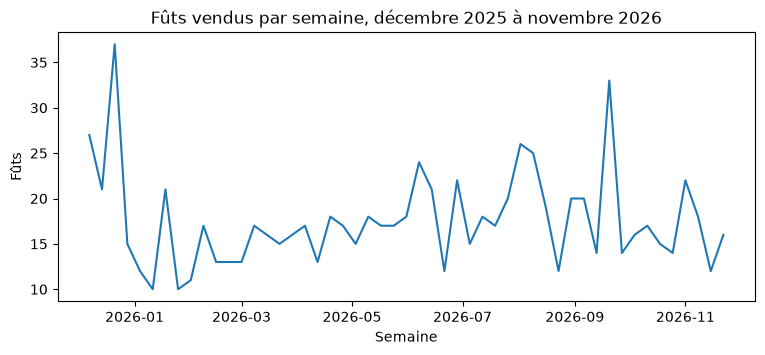

In [38]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(semaines.index, semaines.values)
ax.set_title("Fûts vendus par semaine, décembre 2025 à novembre 2026")
ax.set_xlabel("Semaine")
ax.set_ylabel("Fûts")
plt.show()

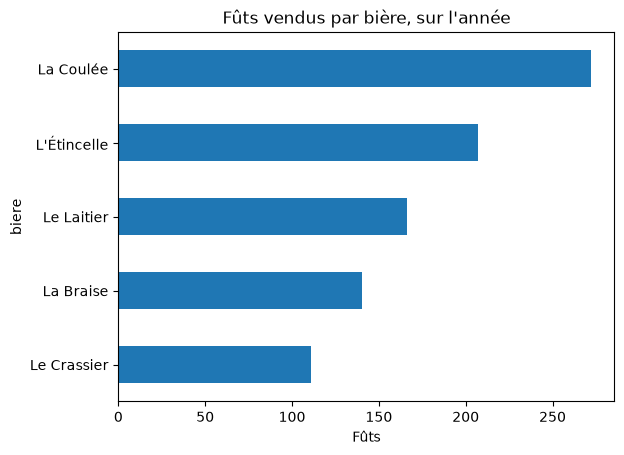

In [39]:
bieres = pd.read_csv("../data/bieres.csv", sep=";")
noms = dict(zip(bieres["code"], bieres["nom"]))
ax = par_biere.rename(index=noms).sort_values().plot(kind="barh", title="Fûts vendus par bière, sur l'année")
ax.set_xlabel("Fûts")
plt.show()

## 8. Atelier — le tableau de bord (J4-62b, J4-63)

Deux cellules fournies : le prix de chaque ligne, puis le fichier des semaines pour demain.

In [40]:
prix = ventes.merge(bieres[["code", "prix_casier", "prix_fut"]],
                    left_on="biere", right_on="code")
prix["prix"] = prix["prix_casier"]
prix.loc[prix["format"] == "fut", "prix"] = prix["prix_fut"]
prix["montant"] = prix["quantite"] * prix["prix"]
print(round(prix["montant"].sum(), 2))

80358.0


In [41]:
export = semaines.rename_axis("semaine").reset_index(name="futs")
export.to_csv("../data/ventes_semaine.csv", sep=";", index=False)
print(pd.read_csv("../data/ventes_semaine.csv", sep=";").shape)

(51, 2)


**Étape 1** Le chiffre d'affaires par bière.

In [42]:
# Votre code ici


**Étape 2** Le chiffre d'affaires par mois, en barres.

In [43]:
# Votre code ici


**Étape 3** Le top 3 des clients en chiffre d'affaires.

In [44]:
# Votre code ici


## 9. Vers le modèle (J4-67)

In [45]:
tableau = pd.read_csv("../data/ventes_semaine.csv", sep=";")
tableau["numero"] = range(len(tableau))
print(tableau.shape, tableau["futs"].mean().round(2))
tableau.head()

(51, 3) 17.57


,semaine,futs,numero
0,2025-12-07,27,0
1,2025-12-14,21,1
2,2025-12-21,37,2
3,2025-12-28,15,3
4,2026-01-04,12,4
